In [1]:
from pathlib import Path
import sys, math, io
import numpy as np
import pandas as pd
import PIL
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display

DATA = Path('data')
if not DATA.exists() and Path('metrics_team_503/data').exists():
    DATA = Path('metrics_team_503/data')
files = ['variant_3_classification.csv', 'variant_8_regression.csv', 'variant_9_recsys.csv']
for filename in files:
    assert (DATA / filename).is_file(), f'Не найден файл {DATA / filename}'
print('Python:', sys.version.split()[0])
print('numpy:', np.__version__, '| pandas:', pd.__version__, '| Pillow:', PIL.__version__)
print('Файлы:', ', '.join(files))


Python: 3.12.14
numpy: 2.3.5 | pandas: 2.2.3 | Pillow: 12.3.0
Файлы: variant_3_classification.csv, variant_8_regression.csv, variant_9_recsys.csv


## Функции для графиков
Следующая ячейка только рисует графики. Сами расчёты находятся ниже в отдельных разделах. Подписи на русском, размеры осей задаются по данным.


In [2]:
def font(size):
    candidates = ['/System/Library/Fonts/Supplemental/Arial.ttf',
                  '/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf',
                  'C:/Windows/Fonts/arial.ttf', 'DejaVuSans.ttf']
    for filename in candidates:
        try:
            return ImageFont.truetype(filename, size)
        except OSError:
            pass
    return ImageFont.load_default(size=size)

def plot(title, xlabel, ylabel, series, limits=None):
    # series: [(подпись, x, y, цвет, вид)]
    image = Image.new('RGB', (1100, 720), 'white')
    draw = ImageDraw.Draw(image)
    left, top, right, bottom = 105, 110, 1040, 565
    xs = np.concatenate([np.asarray(s[1], dtype=float) for s in series])
    ys = np.concatenate([np.asarray(s[2], dtype=float) for s in series])
    if limits is None:
        xmin, xmax, ymin, ymax = xs.min(), xs.max(), ys.min(), ys.max()
        dx = (xmax - xmin) * .06 or 1
        dy = (ymax - ymin) * .08 or 1
        xmin, xmax, ymin, ymax = xmin-dx, xmax+dx, ymin-dy, ymax+dy
    else:
        xmin, xmax, ymin, ymax = limits
    def xy(x, y):
        return (left+(float(x)-xmin)/(xmax-xmin)*(right-left),
                bottom-(float(y)-ymin)/(ymax-ymin)*(bottom-top))
    draw.text((left, 28), title, font=font(27), fill='#172b40')
    for value in np.linspace(xmin, xmax, 6):
        x, _ = xy(value, ymin)
        draw.line((x, top, x, bottom), fill='#e3e8ef')
        draw.text((x, bottom+12), f'{value:.3g}', anchor='mt', font=font(17), fill='#334155')
    for value in np.linspace(ymin, ymax, 6):
        _, y = xy(xmin, value)
        draw.line((left, y, right, y), fill='#e3e8ef')
        draw.text((left-12, y), f'{value:.3g}', anchor='rm', font=font(17), fill='#334155')
    draw.text((left, 78), ylabel, font=font(18), fill='#334155')
    draw.text(((left+right)/2, bottom+49), xlabel, anchor='mt', font=font(18), fill='#334155')
    for label, x, y, color, kind in series:
        points = [xy(a,b) for a,b in zip(x,y)]
        if kind == 'scatter':
            for a,b in points:
                draw.ellipse((a-3,b-3,a+3,b+3), fill=color)
        elif kind == 'bars':
            width = (right-left)/(xmax-xmin) * (x[1]-x[0])*.85 if len(x)>1 else 15
            for a,b in points:
                base=xy(xmin,0)[1]
                draw.rectangle((a-width/2,min(b,base),a+width/2,max(b,base)),fill=color)
        elif len(points)>1:
            draw.line(points, fill=color, width=3)
    draw.rectangle((left,top,right,bottom),outline='#64748b',width=1)
    xx=left
    for label, _, _, color, _ in series:
        if label:
            draw.line((xx,670,xx+24,670),fill=color,width=5)
            draw.text((xx+32,670),label,anchor='lm',font=font(16),fill='#334155')
            xx += 45 + draw.textlength(label,font=font(16))
    display(image)

def confusion_plot(matrix):
    image=Image.new('RGB',(900,590),'white'); d=ImageDraw.Draw(image)
    d.text((50,25),'Спам: матрица ошибок исходного y_pred',font=font(27),fill='#172b40')
    d.text((265,95),'Прогноз 0: обычное',font=font(20),fill='black')
    d.text((570,95),'Прогноз 1: спам',font=font(20),fill='black')
    names=[['TN','FP'],['FN','TP']]
    for row in range(2):
        d.text((25,230+row*170),'Факт '+str(row),font=font(20),fill='black')
        for col in range(2):
            x=240+col*300; y=145+row*170
            d.rectangle((x,y,x+275,y+150),fill='#dcecf8' if row==col else '#fce0dc')
            d.text((x+137,y+75),f'{names[row][col]} = {matrix[row,col]}',anchor='mm',font=font(29),fill='#172b40')
    d.text((240,525),'Строки — факт, столбцы — прогноз.',font=font(20),fill='#334155')
    display(image)


## 1 Классификация: спам
`y_true` — правильная метка, `y_pred` — исходное решение модели, `y_score` — оценка класса 1. Считаем класс 1 спамом, класс 0 обычным сообщением.

FP — обычное сообщение ошибочно пометили спамом. FN — спам пропустили. Строки без идентификатора не удаляем как дубликаты: одинаковые значения могут относиться к разным сообщениям.


Строк: 350 | пропусков: 0
Доля класса 1: 37.14%
Несовпадения y_pred и решения при пороге 0,5: 0
Базовое правило «всегда обычное»: accuracy = 0.6286, recall = 0.


,y_true,y_pred,y_score
0,0,1,0.823
1,1,1,0.599
2,0,1,0.637
3,1,1,0.569
4,1,0,0.411


,TN,FP,FN,TP,signals,accuracy,precision,recall,F1
Исходный y_pred,168,52,29,101,153,0.7686,0.6601,0.7769,0.7138


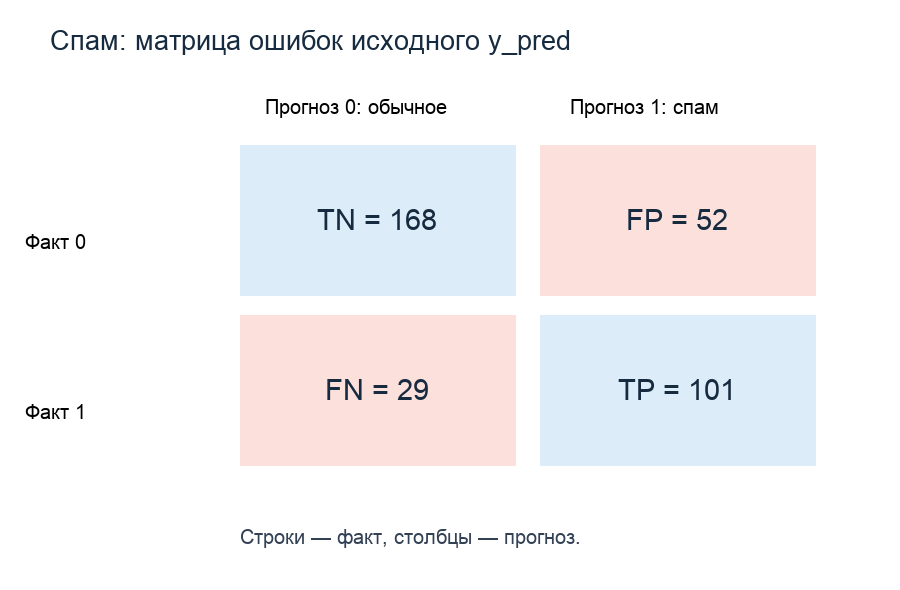

In [3]:
classification = pd.read_csv(DATA / files[0])
assert list(classification.columns) == ['y_true','y_pred','y_score']
assert classification.isna().sum().sum() == 0
assert classification['y_true'].isin([0,1]).all()
assert classification['y_pred'].isin([0,1]).all()
assert classification['y_score'].between(0,1).all()
y = classification['y_true'].to_numpy(dtype=int)
pred = classification['y_pred'].to_numpy(dtype=int)
score = classification['y_score'].to_numpy(dtype=float)
print('Строк:', len(y), '| пропусков:', classification.isna().sum().sum())
print(f'Доля класса 1: {y.mean():.2%}')
print('Несовпадения y_pred и решения при пороге 0,5:', int(np.sum(pred != (score >= .5))))
display(classification.head())

def binary_metrics(y, predicted):
    tp=int(np.sum((y==1)&(predicted==1)))
    tn=int(np.sum((y==0)&(predicted==0)))
    fp=int(np.sum((y==0)&(predicted==1)))
    fn=int(np.sum((y==1)&(predicted==0)))
    precision=tp/(tp+fp) if tp+fp else 0.0
    recall=tp/(tp+fn) if tp+fn else 0.0
    f1=2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 0.0
    return dict(TN=tn,FP=fp,FN=fn,TP=tp,signals=tp+fp,
                accuracy=(tp+tn)/len(y),precision=precision,recall=recall,F1=f1)

original = binary_metrics(y,pred)
display(pd.DataFrame([original],index=['Исходный y_pred']).round(4))
print(f'Базовое правило «всегда обычное»: accuracy = {1-y.mean():.4f}, recall = 0.')
confusion_plot(np.array([[original['TN'],original['FP']],[original['FN'],original['TP']]]))


### ROC AUC, AP и LogLoss
Для ROC и PR объединяем одинаковые score в один порог. ROC AUC считаем по трапециям ROC-кривой. AP считаем как сумму прироста recall, умноженного на precision; это **AP, а не площадь PR по трапециям**.

Для LogLoss отдельно предполагаем, что `y_score` можно трактовать как вероятность спама. Данные не доказывают, что эти вероятности откалиброваны.


,Метрика,Значение
0,ROC AUC,0.8549
1,AP,0.7874
2,LogLoss (score как вероятность),0.4776


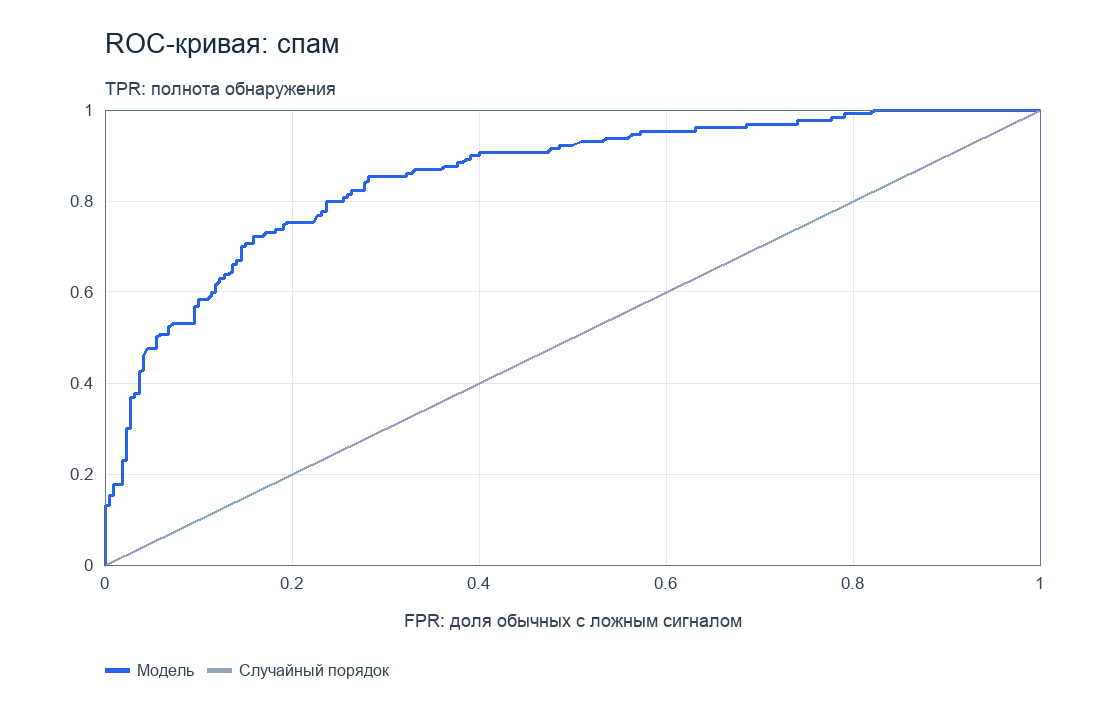

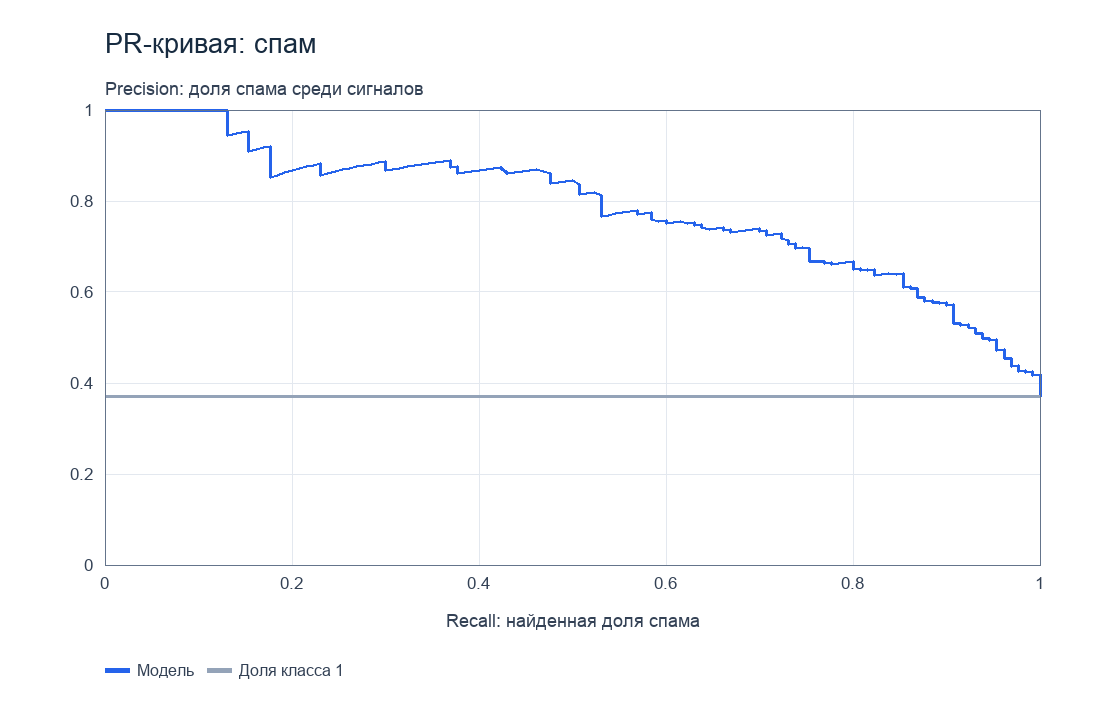

In [4]:
order=np.argsort(-score,kind='stable')
sorted_y=y[order]
sorted_score=score[order]
ends=np.r_[np.flatnonzero(np.diff(sorted_score)!=0),len(y)-1]
tp=np.cumsum(sorted_y)[ends]
fp=(ends+1)-tp
positive=int(y.sum()); negative=len(y)-positive
recall_curve=tp/positive
precision_curve=tp/(tp+fp)
tpr=np.r_[0,recall_curve]
fpr=np.r_[0,fp/negative]
roc_auc=float(np.sum(np.diff(fpr)*(tpr[1:]+tpr[:-1])/2))
ap=float(np.sum(np.diff(np.r_[0,recall_curve])*precision_curve))
prob=np.clip(score,1e-15,1-1e-15)
logloss=float(-np.mean(y*np.log(prob)+(1-y)*np.log(1-prob)))
display(pd.DataFrame({'Метрика':['ROC AUC','AP','LogLoss (score как вероятность)'],
                      'Значение':[roc_auc,ap,logloss]}).round(4))
plot('ROC-кривая: спам','FPR: доля обычных с ложным сигналом','TPR: полнота обнаружения',
     [('Модель',fpr,tpr,'#2563eb','line'),('Случайный порядок',[0,1],[0,1],'#94a3b8','line')],(0,1,0,1))
plot('PR-кривая: спам','Recall: найденная доля спама','Precision: доля спама среди сигналов',
     [('Модель',np.r_[0,recall_curve],np.r_[1,precision_curve],'#2563eb','line'),
      ('Доля класса 1',[0,1],[y.mean(),y.mean()],'#94a3b8','line')],(0,1,0,1))


In [5]:
threshold_rows=[]
for threshold in [.3,.5,.8]:
    row=binary_metrics(y,(score>=threshold).astype(int))
    threshold_rows.append({'Порог':threshold,**row})
thresholds=pd.DataFrame(threshold_rows)
display(thresholds[['Порог','signals','FP','FN','precision','recall','F1']].round(4))
# Проверка количества сообщений в исходной матрице.
assert sum(original[k] for k in ['TN','FP','FN','TP']) == len(y)
# Независимая проверка ROC AUC сравнением всех пар классов, включая равные score.
pairwise=score[y==1,None]-score[y==0][None,:]
auc_check=float(np.mean((pairwise>0)+.5*(pairwise==0)))
assert np.isclose(roc_auc,auc_check)
print(f'Ручная проверка precision: {original["TP"]} / ({original["TP"]} + {original["FP"]}) = {original["precision"]:.4f}')


Ручная проверка precision: 101 / (101 + 52) = 0.6601


,Порог,signals,FP,FN,precision,recall,F1
0,0.3,229,109,10,0.5240,0.9231,0.6685
1,0.5,153,52,29,0.6601,0.7769,0.7138
2,0.8,47,6,89,0.8723,0.3154,0.4633


### Вывод по спаму
При пороге 0,5 получаем 52 ложных срабатывания и 29 пропусков. Precision около 66%, recall около 78%: модель находит большую часть спама, но часть обычных сообщений тоже помечает как спам.

При 0,3 пропусков меньше — 10, но ложных сигналов уже 109. При 0,8 ложных сигналов только 6, зато пропускаем 89 спам-сообщений.

Для автоматического переноса в папку «Спам» основной метрикой предлагаем **precision**, чтобы реже прятать обычные сообщения. Ограничение — recall, чтобы фильтр не пропускал слишком много спама. Из трёх порогов 0,8 даёт самый высокий precision, но низкий recall; это кандидат для дальнейшей проверки, а не готовый выбор для запуска. Для предупреждения без скрытия сообщения допустим другой баланс.

Дальше нужно согласовать допустимые FP и FN, проверить спорные сообщения и протестировать выбранный порог на другом наборе. **Данных для решения о запуске недостаточно.**


## 2 Регрессия: LTV
LTV — суммарная ценность клиента за выбранный период. В учебном файле конкретные денежные единицы и период не указаны, поэтому используем «единицы данных».

Остаток = факт − прогноз. Положительный остаток означает недооценку, отрицательный — переоценку.


In [6]:
regression=pd.read_csv(DATA / files[1])
assert list(regression.columns)==['y_true','y_pred']
assert regression.isna().sum().sum()==0
actual=regression['y_true'].to_numpy(float)
forecast=regression['y_pred'].to_numpy(float)
assert np.isfinite(actual).all() and np.isfinite(forecast).all()
residual=actual-forecast
absolute=np.abs(residual)
print('Строк:',len(actual),'| пропусков:',regression.isna().sum().sum())
print(f'Факт: от {actual.min():.2f} до {actual.max():.2f}; нулевых фактов: {(actual==0).sum()}')
print(f'Прогноз: от {forecast.min():.2f} до {forecast.max():.2f}; нулевых прогнозов: {(forecast==0).sum()}')
display(regression.head())
mae=float(absolute.mean()); mse=float(np.mean(residual**2)); rmse=math.sqrt(mse)
r2=float(1-np.sum(residual**2)/np.sum((actual-actual.mean())**2))
# При наличии нулевого факта обычный MAPE по всему набору не определён.
mape=float(np.mean(absolute/np.abs(actual))*100) if np.all(actual!=0) else float('nan')
reg_metrics=pd.DataFrame({'Метрика':['MAE','MSE','RMSE','R²','MAPE, %','Средний остаток'],
                         'Значение':[mae,mse,rmse,r2,mape,residual.mean()],
                         'Единицы':['единицы данных','единицы данных²','единицы данных','безразмерно','%','единицы данных']})
display(reg_metrics.round(4))
print(f'R² сравнивает с постоянным прогнозом среднего факта: {actual.mean():.2f}.')
print('Это описательный базовый уровень на данном наборе, не прогноз для новых клиентов.')


Строк: 350 | пропусков: 0
Факт: от 4.53 до 398.83; нулевых фактов: 0
Прогноз: от 0.00 до 420.51; нулевых прогнозов: 9
R² сравнивает с постоянным прогнозом среднего факта: 116.78.
Это описательный базовый уровень на данном наборе, не прогноз для новых клиентов.


,y_true,y_pred
0,99.48,77.94
1,268.24,270.68
2,40.81,35.14
3,195.76,211.99
4,111.53,100.19


,Метрика,Значение,Единицы
0,MAE,20.0687,единицы данных
1,MSE,645.7394,единицы данных²
2,RMSE,25.4114,единицы данных
3,R²,0.8879,безразмерно
4,"MAPE, %",26.3771,%
5,Средний остаток,-0.4700,единицы данных


Пять наибольших абсолютных ошибок:
Пять наименьших фактических LTV:
90-й процентиль абсолютной ошибки: 41.56
Доля недооценок: 51.14%; переоценок: 48.86%
Проверка первой строки: |99.48 − 77.94| = 21.54


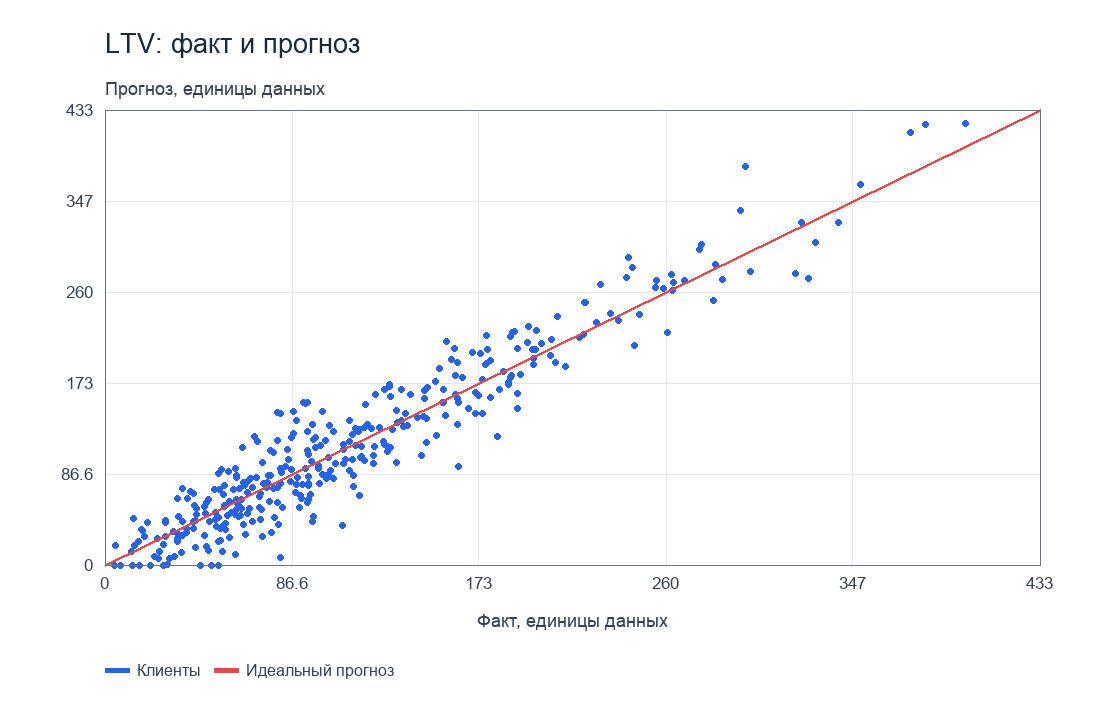

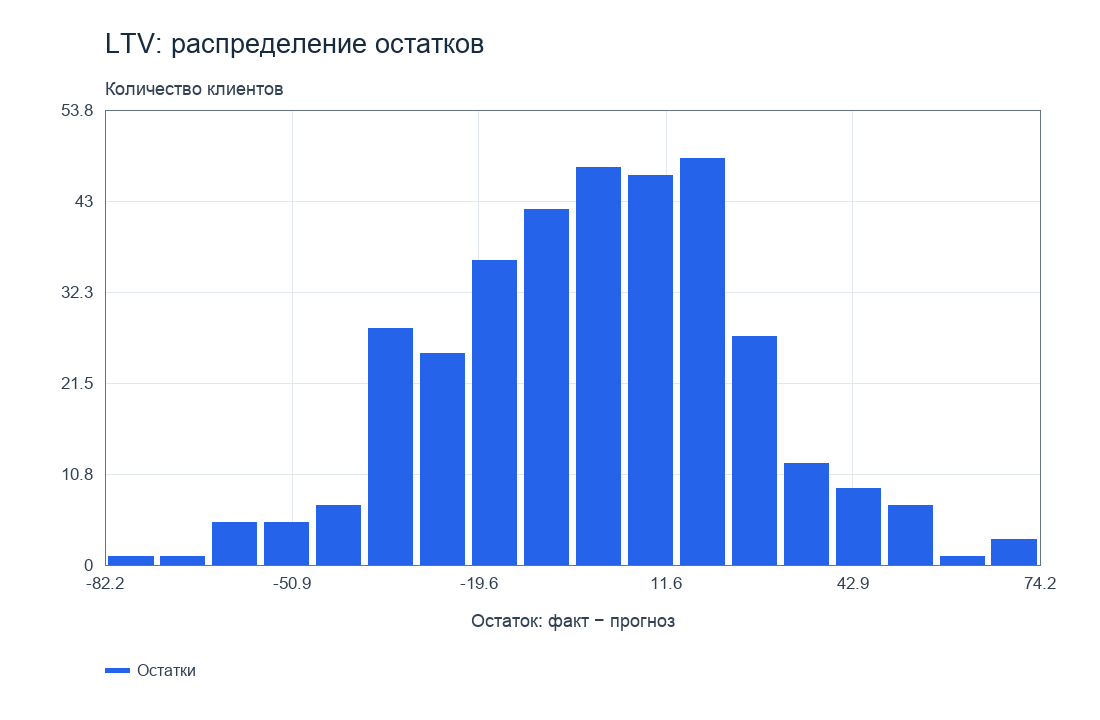

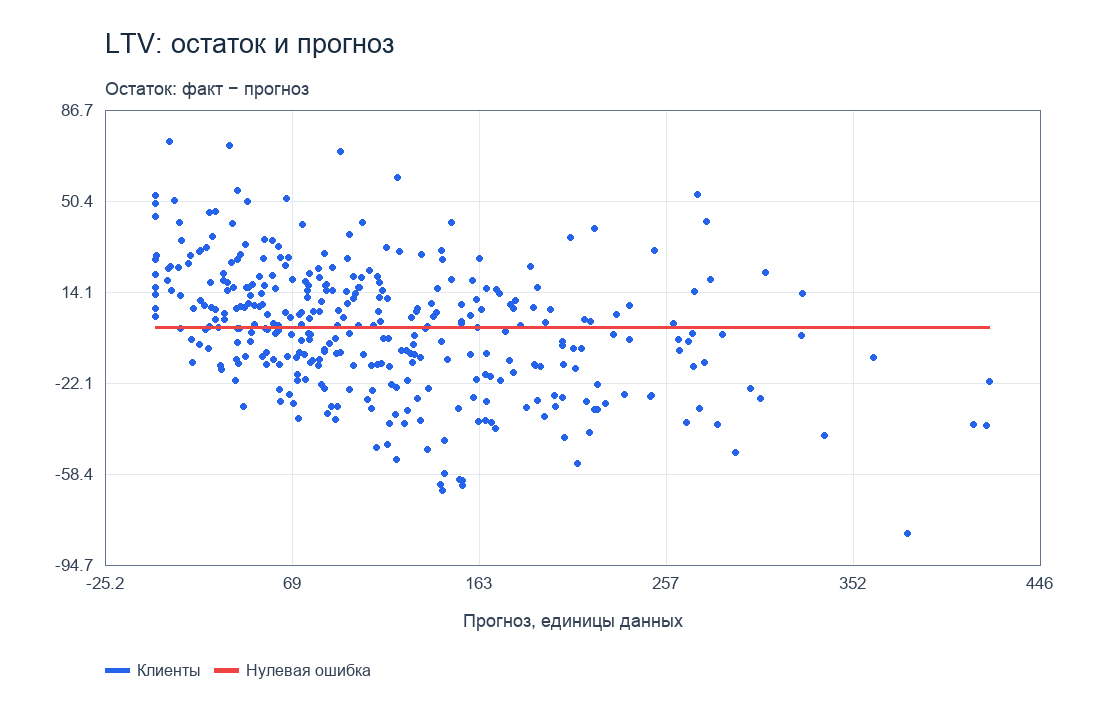

,y_true,y_pred,Остаток,Абсолютная ошибка,"Ошибка, %"
Строка данных,,,,,
103,296.71,378.90,-82.19,82.19,27.70
282,81.34,7.17,74.17,74.17,91.19
160,109.95,37.23,72.72,72.72,66.14
326,163.61,93.61,70.00,70.00,42.78
250,79.80,144.87,-65.07,65.07,81.54


,y_true,y_pred,Остаток,Абсолютная ошибка,"Ошибка, %"
Строка данных,,,,,
113,4.53,0.00,4.53,4.53,100.00
229,4.68,18.79,-14.11,14.11,301.50
10,7.38,0.00,7.38,7.38,100.00
78,12.25,12.70,-0.45,0.45,3.67
252,12.96,0.00,12.96,12.96,100.00


In [7]:
bound=max(actual.max(),forecast.max())*1.03
plot('LTV: факт и прогноз','Факт, единицы данных','Прогноз, единицы данных',
     [('Клиенты',actual,forecast,'#2563eb','scatter'),('Идеальный прогноз',[0,bound],[0,bound],'#ef4444','line')],(0,bound,0,bound))
counts,edges=np.histogram(residual,bins=18)
centers=(edges[:-1]+edges[1:])/2
plot('LTV: распределение остатков','Остаток: факт − прогноз','Количество клиентов',
     [('Остатки',centers,counts,'#2563eb','bars')],(edges[0],edges[-1],0,counts.max()*1.12))
plot('LTV: остаток и прогноз','Прогноз, единицы данных','Остаток: факт − прогноз',
     [('Клиенты',forecast,residual,'#2563eb','scatter'),('Нулевая ошибка',[forecast.min(),forecast.max()],[0,0],'#ef4444','line')])
errors=regression.copy()
errors['Остаток']=residual
errors['Абсолютная ошибка']=absolute
errors['Ошибка, %']=absolute/np.abs(actual)*100
errors.index=np.arange(1,len(errors)+1)
errors.index.name='Строка данных'
print('Пять наибольших абсолютных ошибок:')
display(errors.nlargest(5,'Абсолютная ошибка').round(2))
print('Пять наименьших фактических LTV:')
display(errors.nsmallest(5,'y_true').round(2))
print(f'90-й процентиль абсолютной ошибки: {np.percentile(absolute,90):.2f}')
print(f'Доля недооценок: {np.mean(residual>0):.2%}; переоценок: {np.mean(residual<0):.2%}')
print(f'Проверка первой строки: |{actual[0]} − {forecast[0]}| = {absolute[0]:.2f}')
assert np.isclose(rmse**2,mse) and rmse>=mae


### Вывод по LTV
MAE около 20,07 единицы данных: на столько модель в среднем промахивается по модулю. RMSE около 25,41, поэтому крупные промахи заметны и их нужно разбирать отдельно. R² около 0,888 означает уменьшение суммы квадратов ошибок относительно постоянного прогноза среднего, а не «88,8% точных ответов».

Средний остаток около −0,47: в среднем прогноз слегка завышен, но это не отменяет больших ошибок по отдельным клиентам. MAPE около 26,38%. Малые фактические LTV сильнее влияют на процентную ошибку, поэтому рядом показаны такие строки.

Для оценки обычного размера промаха предлагаем **MAE** как основную метрику. Ограничение — RMSE и ошибки клиентов с большим LTV. Эти ошибки могут привести к неправильному бюджету привлечения или удержания.

Дальше нужно уточнить период LTV и единицы, проверить ошибки по сегментам и на новых данных, сравнить с простым прогнозом, рассчитанным только на обучающей истории. Допустимую ошибку нужно связать с бюджетом продукта. **Данных для решения о запуске недостаточно.**


## 3 Рекомендации: товары
Одна строка — один пользователь. `recommended_items` — рекомендации в исходном порядке, `relevant_items` — известные подходящие товары. Списки разделены точкой с запятой.

Основной расчёт — при k = 10. Precision@k делим на k даже при коротком списке. AP@k делим на min(число релевантных, k). RR считаем по всему переданному списку. NDCG использует полезность 0/1. Сначала считаем показатели каждого пользователя, затем обычное среднее.


Пользователей: 120
Повторяющихся user_id: 0
Длины рекомендаций: [10]
Длины релевантных списков: [1, 2, 3]
Пустых релевантных списков: 0
Списков с повторами в рекомендациях: 0
Списков с повторами в релевантных: 0
Без попаданий в первых 10: 102 из 120 (85.0%)


,user_id,recommended_items,relevant_items
0,1,3;36;27;64;47;43;23;5;11;31,85;68
1,2,61;93;14;44;48;25;94;45;75;68,72;94
2,3,58;10;33;49;20;92;82;79;9;72,46
3,4,32;38;86;94;39;50;76;57;27;8,8;55
4,5,65;71;64;60;87;11;55;88;7;15,93;76


,user_id,hits,precision,recall,AP,RR,NDCG
0,1,0,0.0,0.0,0.0000,0.0000,0.0000
1,2,1,0.1,0.5,0.0714,0.1429,0.2044
2,3,0,0.0,0.0,0.0000,0.0000,0.0000
3,4,1,0.1,0.5,0.0500,0.1000,0.1772
4,5,0,0.0,0.0,0.0000,0.0000,0.0000
5,6,0,0.0,0.0,0.0000,0.0000,0.0000
6,7,0,0.0,0.0,0.0000,0.0000,0.0000
7,8,0,0.0,0.0,0.0000,0.0000,0.0000
8,9,0,0.0,0.0,0.0000,0.0000,0.0000
9,10,0,0.0,0.0,0.0000,0.0000,0.0000


,Метрика,Значение
0,Средняя precision@10,0.0150
1,Средняя recall@10,0.0778
2,MAP@10,0.0214
3,MRR (весь список),0.0424
4,Средняя NDCG@10,0.0411


,k,precision,recall
0,1,0.0167,0.0083
1,2,0.0125,0.0111
2,3,0.0167,0.0250
3,4,0.0125,0.0250
4,5,0.0117,0.0278
5,6,0.0111,0.0361
6,7,0.0131,0.0472
7,8,0.0146,0.0597
8,9,0.0148,0.0708
9,10,0.0150,0.0778


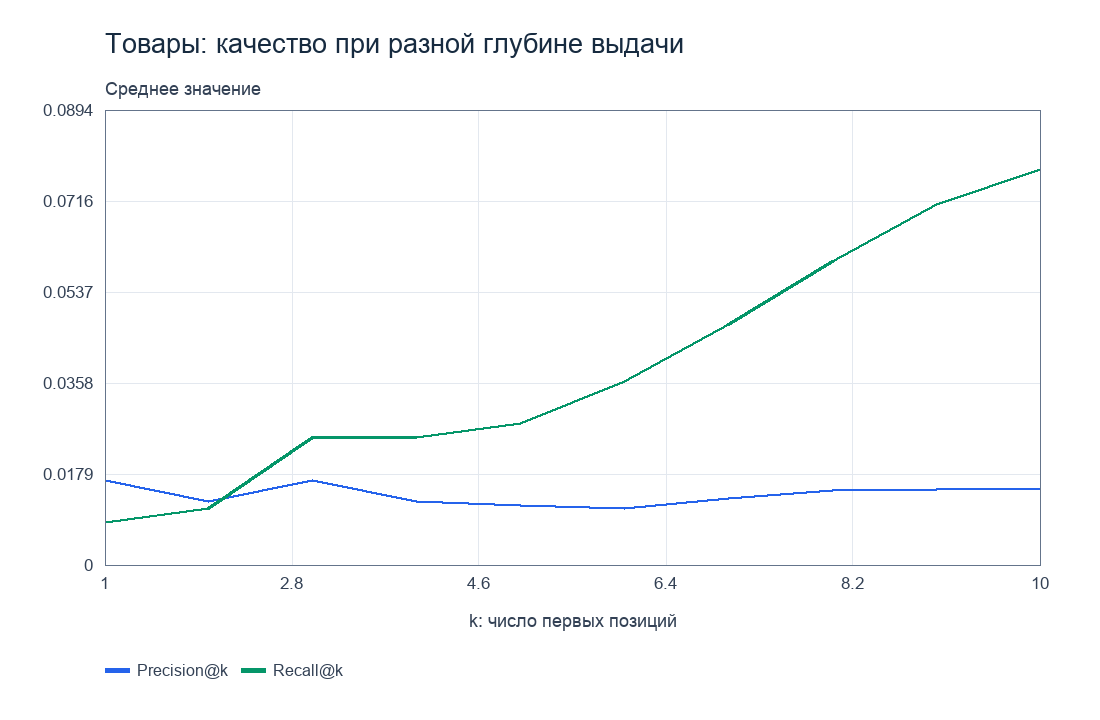

In [8]:
recommendations=pd.read_csv(DATA / files[2],keep_default_na=False)
assert list(recommendations.columns)==['user_id','recommended_items','relevant_items']
def parse_items(value):
    return [int(x.strip()) for x in str(value).split(';') if x.strip()]
rec_lists=recommendations['recommended_items'].map(parse_items).tolist()
rel_lists=recommendations['relevant_items'].map(parse_items).tolist()
print('Пользователей:',len(recommendations))
print('Повторяющихся user_id:',recommendations['user_id'].duplicated().sum())
print('Длины рекомендаций:',sorted(set(map(len,rec_lists))))
print('Длины релевантных списков:',sorted(set(map(len,rel_lists))))
print('Пустых релевантных списков:',sum(not x for x in rel_lists))
print('Списков с повторами в рекомендациях:',sum(len(x)!=len(set(x)) for x in rec_lists))
print('Списков с повторами в релевантных:',sum(len(x)!=len(set(x)) for x in rel_lists))
assert not recommendations['user_id'].duplicated().any()
assert all(len(x)==len(set(x)) for x in rec_lists)
assert all(len(x)==len(set(x)) for x in rel_lists)
assert all(len(x)>0 for x in rel_lists), 'Нужно отдельно согласовать правило для пустой релевантности'
display(recommendations.head())

def user_metrics(recs,relevant,k=10):
    relevant=set(relevant)
    hits=[int(item in relevant) for item in recs[:k]]
    count=sum(hits)
    precision=count/k
    recall=count/len(relevant)
    cumulative=0
    numerator=0.0
    for position,hit in enumerate(hits,start=1):
        cumulative+=hit
        if hit:
            numerator+=cumulative/position
    ap=numerator/min(len(relevant),k)
    first=next((i for i,item in enumerate(recs,start=1) if item in relevant),None)
    rr=1/first if first else 0.0
    dcg=sum(hit/math.log2(i+1) for i,hit in enumerate(hits,start=1))
    idcg=sum(1/math.log2(i+1) for i in range(1,min(len(relevant),k)+1))
    return dict(hits=count,precision=precision,recall=recall,AP=ap,RR=rr,NDCG=dcg/idcg)

per_user=pd.DataFrame([user_metrics(a,b,10) for a,b in zip(rec_lists,rel_lists)])
per_user.insert(0,'user_id',recommendations['user_id'])
display(per_user.head(12).round(4))
rec_mean=per_user[['precision','recall','AP','RR','NDCG']].mean()
display(pd.DataFrame({'Метрика':['Средняя precision@10','Средняя recall@10','MAP@10','MRR (весь список)','Средняя NDCG@10'],
                      'Значение':rec_mean.to_numpy()}).round(4))
print(f'Без попаданий в первых 10: {(per_user.hits==0).sum()} из {len(per_user)} ({np.mean(per_user.hits==0):.1%})')
curves=[]
for k in range(1,11):
    rows=[user_metrics(a,b,k) for a,b in zip(rec_lists,rel_lists)]
    curves.append({'k':k,'precision':np.mean([r['precision'] for r in rows]),
                   'recall':np.mean([r['recall'] for r in rows])})
curves=pd.DataFrame(curves)
display(curves.round(4))
plot('Товары: качество при разной глубине выдачи','k: число первых позиций','Среднее значение',
     [('Precision@k',curves.k,curves.precision,'#2563eb','line'),
      ('Recall@k',curves.k,curves.recall,'#059669','line')],(1,10,0,max(curves.precision.max(),curves.recall.max())*1.15))


In [9]:
# Берём реальную строку с попаданием для ручной проверки.
j=int(np.flatnonzero(per_user['hits'].to_numpy()>0)[0])
a=rec_lists[j]; b=set(rel_lists[j])
positions=[i for i,item in enumerate(a[:10],start=1) if item in b]
print('Ручной пример. user_id =',recommendations.iloc[j]['user_id'])
print('Рекомендации:',a)
print('Релевантные товары:',sorted(b))
print('Попадания на позициях:',positions)
print(f'Precision@10 = {len(positions)} / 10 = {len(positions)/10:.4f}')
print(f'Recall@10 = {len(positions)} / {len(b)} = {len(positions)/len(b):.4f}')
terms=[f'{number}/{position}' for number,position in enumerate(positions,start=1)]
ap_manual=sum(number/position for number,position in enumerate(positions,start=1))/min(len(b),10)
rr_manual=1/positions[0]
dcg_manual=sum(1/math.log2(position+1) for position in positions)
idcg_manual=sum(1/math.log2(i+1) for i in range(1,min(len(b),10)+1))
print(f'AP@10 = ({" + ".join(terms)}) / {min(len(b),10)} = {ap_manual:.4f}')
print(f'RR = 1 / {positions[0]} = {rr_manual:.4f}')
print(f'NDCG@10 = {dcg_manual:.4f} / {idcg_manual:.4f} = {dcg_manual/idcg_manual:.4f}')
assert np.isclose(ap_manual,per_user.iloc[j]['AP'])
assert np.isclose(dcg_manual/idcg_manual,per_user.iloc[j]['NDCG'])
# Одинаковое число попаданий не гарантирует одинаковое качество порядка.
reordered=[x for x in a if x in b]+[x for x in a if x not in b]
display(pd.DataFrame([user_metrics(a,b),user_metrics(reordered,b)],
                     index=['Исходный порядок','Попадания перенесены вверх']).round(4))
print('Перестановка показывает смысл метрик порядка, но не является новой проверенной моделью.')


Ручной пример. user_id = 2
Рекомендации: [61, 93, 14, 44, 48, 25, 94, 45, 75, 68]
Релевантные товары: [72, 94]
Попадания на позициях: [7]
Precision@10 = 1 / 10 = 0.1000
Recall@10 = 1 / 2 = 0.5000
AP@10 = (1/7) / 2 = 0.0714
RR = 1 / 7 = 0.1429
NDCG@10 = 0.3333 / 1.6309 = 0.2044
Перестановка показывает смысл метрик порядка, но не является новой проверенной моделью.


,hits,precision,recall,AP,RR,NDCG
Исходный порядок,1,0.1,0.5,0.0714,0.1429,0.2044
Попадания перенесены вверх,1,0.1,0.5,0.5000,1.0000,0.6131


### Вывод по рекомендациям
У 102 из 120 пользователей в первых десяти рекомендациях нет ни одного известного подходящего товара — это 85%. В среднем приходится 0,15 попадания на список, поэтому средняя precision@10 равна 1,5%.

Нужен не только подходящий товар в списке, но и хорошее место: пользователь может не дойти до конца. Для выдачи товаров предлагаем **NDCG@10** как основную метрику порядка. Ограничения — доля пользователей без попаданий и recall@10. MRR отдельно показывает, насколько рано встречается первый подходящий товар.

Следующий шаг — проверить полноту списка релевантных товаров, способ построения кандидатов и сравнить выдачу с простым базовым вариантом, например популярными товарами. Данных для расчёта такого базового варианта в этих файлах нет. Отсутствие товара в релевантном списке здесь считаем нулевой полезностью по учебному правилу; в реальности это может означать отсутствие наблюдения. **Данных для решения о запуске недостаточно.**


## 4 Общий итог

| Кейс | Основная метрика | Ограничение | Следующий шаг |
| --- | --- | --- | --- |
| Спам | Precision для переноса в папку «Спам» | Recall и допустимое число FP | Согласовать последствия ошибок, проверить порог на другом наборе |
| LTV | MAE | RMSE и крупные ошибки по сегментам | Уточнить период, единицы и допустимый промах, проверить на новых данных |
| Товары | NDCG@10 | Доля без попаданий и recall@10 | Проверить релевантность и сравнить с базовой выдачей |

Значения метрик описывают эти учебные наборы. Требования к запуску в задании не заданы, поэтому по одному расчёту модель не запускаем.

## 5 Метрика для нашего проекта
Для проекта «Поиск первой ИТ стажировки без опыта» предлагаем техническую метрику: **precision подтверждений навыков** — число корректных подтверждений, делённое на число всех выданных подтверждений. Корректность нужно размечать вручную по тексту вакансии и описанию проекта.

Она нужна, чтобы разбор не приписывал студенту навыки без основания. Дополнительно смотрим на пропущенные подтверждения и требования. Случаи «нет информации» сохраняем отдельно. Если система вообще не выдала подтверждений, precision не определена, а не равна 100%.

Это предложение для обсуждения командой, не уже измеренный результат. Для текущего ручного прототипа можно так же оценивать качество разборов. Пользовательский результат из С4 — обоснованный выбор стажировки и следующий шаг — проверяем отдельно: техническая точность его не заменяет.

## 6 Проверка и использование ИИ
Матрица ошибок сверена с числом строк, ROC AUC дополнительно проверен сравнением пар классов. Для регрессии проверена связь RMSE и MSE и показан расчёт одной ошибки. Для рекомендаций один пользователь разобран вручную, проверены знаменатели и порядок.

ИИ использован для уточнения определений, понимания задания, подготовки кода, расчётов и объяснений. Фактический вклад остальных участников в выполнение и взаимную проверку пока не подтверждён. Перед сдачей команда должна проверить расчёты и указать выполненный вклад без замены будущих задач уже сделанными.

Источники: задание Seminar_10.pdf, лекция Lekciya_4_ekran.pdf и три исходных CSV из students.zip. В названии файла задания указан номер 10, внутри — семинар 7. Номера вариантов выбраны по строке 3 таблицы распределения.
